# Setup

## Imports

In [51]:
%load_ext autoreload
%autoreload 2

import json

## IMPORTS
import os
from typing import Literal

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import KDTree, cKDTree
from shapely.geometry import Point, box
from shapely.ops import unary_union

import src.data_filepaths as data_filepaths
import src.utils.loaders as loaders
import src.utils.vis.colors_utils as colors_utils
from src.utils.df_tools import map_values_b_to_bp, shuffle_df
from src.utils.loaders import (
    load_boundary_pln_area,
    load_boundary_pln_region,
    load_boundary_subzone,
    process_loaded_building_df,
)
from src.utils.vis.map import CategoricalColorMap, MapExplorer
from src.utils.vis.map_special import (
    build_map_building_basic,
    build_map_point_floorspace_demand_type,
    build_map_point_numeric_and_category,
)

# configs
sns.set_theme()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [52]:
ALLOW_EXPORT = True

## Loading

In [53]:
#### LOAD

## boundaries
pln_region_gdf = load_boundary_pln_region()
pln_area_gdf = load_boundary_pln_area()
subzone_gdf = load_boundary_subzone()

print(f"There are {len(pln_region_gdf)} planning regions, {len(pln_area_gdf)} planning areas, and {len(subzone_gdf)} subzones")

## demand
# buildings
buildings_gdf = gpd.read_parquet(
    os.path.join(
        data_filepaths.path_data_intermediate,
        "buildings_v2.parquet",
    )
)
# remove hotels
buildings_gdf = buildings_gdf[~buildings_gdf["demand_type"].isin(["hotel"])]

# special_demand
sd_health_gdf = gpd.read_parquet(
    os.path.join(
        data_filepaths.path_data_intermediate,
        "healthcare_workforce_v1.parquet",
    )
)
sd_mil_gdf = gpd.read_parquet(
    os.path.join(
        data_filepaths.path_data_intermediate,
        "military_workforce_v1.parquet",
    )
)
sd_gov_gdf = gpd.read_parquet(
    os.path.join(
        data_filepaths.path_data_intermediate,
        "gov_workforce_v1.parquet",
    )
)

There are 5 planning regions, 55 planning areas, and 332 subzones


## Total Workforce Calculation

Computes a finalised total residences, total workplaces, and residences/workplaces to be computed

Non-resident workforce:

* 1.91 million non-resident workforce
* 41% (~783k) are EP/SP + WP (non-CMP) - all included
* Out of the 23% WC (CMP), take only 20% (~90k)

Land Border Commuters:

* See Notion for more details, but the TL;DR is that using a combination of current ICA crossing data 
  (~510k/day), and a 2017 ISEAS estimate of 120k Malaysian commuters, I estimate 150k daily commuters
  that cross to work in Singapore in 2025.

In [54]:
# note that this differs from the official workforce statistic at 2.481M
# this starts with the total employed by residence pln_area (includes "other"), 
# then excludes the ~80k WFH that was recorded later
WORKFORCE_COUNT_BASE_RESIDENT = 2379300 - 81200

# see above or Notion
LAND_BORDER_COMMUTERS = 150000

# ~870000 - 150000 = ~750000
WORKFORCE_COUNT_NON_RESIDENT = 1910000 * (0.41 + 0.23 * 0.2) - LAND_BORDER_COMMUTERS

In [55]:
RESIDENCE_TOTAL = WORKFORCE_COUNT_BASE_RESIDENT + WORKFORCE_COUNT_NON_RESIDENT
WORKFORCE_TOTAL = WORKFORCE_COUNT_BASE_RESIDENT + WORKFORCE_COUNT_NON_RESIDENT

# Population/Workplace at Statistical Levels

Key input datasets:

* Resident population by **Subzone** of *Residence* (GHS2025)
* Employed residents by **Planning Area** of *Residence* (GHS2025)
* Employed residents by **Planning Area** of *Workplace* & **Planning Region** of *Residence* (GHS2025)


## Data Loading and Cleanup

In [56]:
### UTILITIES

def reformat_location_name(name: str):
    """
    Reformats `  Location Name` (with possible leading spaces) to `LOCATION NAME`.

    Removes trailing spaces as well, not I've noticed those to be present
    """
    return name.strip().upper()

In [57]:
def load_res_subzone():
    """
    Just ignores the header, I only care about the first two columns anyway

    Also just loads the first two columns: the subzone row index, and the totals for each subzone

    ### Data:
    There are no known data issues here. The data also includes subzones that have zero population.
    All 332 subzones are represented in the data.
    """

    fname = "C020126-clean.csv"
    fpath = os.path.join(data_filepaths.path_sgdata_resident, fname)

    # takes first two columns
    df = pd.read_csv(fpath, header=None, skiprows=2).iloc[:, :2]
    df.columns = ["subzone_name", "res_pop_residence"]
    df["res_pop_residence"] = df["res_pop_residence"].replace("-", "0").astype(float)

    # drops the "<PLN_AREA> - Total" rows and the first "Total" row - so drop all that contain "Total"
    df = df[~df["subzone_name"].str.contains("Total")]

    df["subzone_name"] = df["subzone_name"].map(reformat_location_name)

    assert df["subzone_name"].isin(subzone_gdf["subzone_name"]).all(), "Subzones not found in subzone_gdf"

    # brings in the correct indexes
    df = df.merge(
        subzone_gdf[["subzone_name", "pln_area_id", "pln_region_id"]].reset_index(),
        left_on="subzone_name",
        right_on="subzone_name",
    ).set_index("subzone_id")

    df = df[["pln_area_id", "pln_region_id", "subzone_name", "res_pop_residence"]]

    return df

data_res_subzone = load_res_subzone()

print(data_res_subzone["res_pop_residence"].sum())

data_res_subzone

4161480.0


,pln_area_id,pln_region_id,subzone_name,res_pop_residence
subzone_id,,,,
AMSZ01,AM,NER,ANG MO KIO TOWN CENTRE,4810.0
AMSZ02,AM,NER,CHENG SAN,26370.0
AMSZ03,AM,NER,CHONG BOON,24260.0
AMSZ06,AM,NER,KEBUN BAHRU,21440.0
AMSZ07,AM,NER,SEMBAWANG HILLS,6790.0
...,...,...,...,...
YSSZ06,YS,NR,SPRINGLEAF,4260.0
YSSZ01,YS,NR,YISHUN CENTRAL,2830.0
YSSZ03,YS,NR,YISHUN EAST,73430.0


In [58]:
def load_employed_res_pln_area():
    """
    Just ignores the header, I only care about the first two columns anyway

    Also just loads the first two columns: the planning area row index, and the totals for each planning area
    The actual data includes counts by income bracket, I had to specify one to even download it

    ### Data:
    * There are only about 29 pln_area in which employed residences reside, out of 55 total
    * The csv includes an `Others` row of about 24000.
        * This likely covers the remaining pln_area, as such that number is also returned at the end
        for later distribution using more precise subzone residential data
        * These missing pln_area will have `work_pop_residence` = NA for now
    * This produces a total population with known residence locations, of 2,355,100.
    """

    fname = "C020138-clean.csv"
    fpath = os.path.join(data_filepaths.path_sgdata_resident, fname)

    # takes first two columns
    df = pd.read_csv(fpath, header=None, skiprows=1).iloc[:, :2]
    df.columns = ["pln_area_name", "work_pop_residence"]
    df["work_pop_residence"] = df["work_pop_residence"].replace("-", "0").astype(float)

    # drops "Total", though there really is just the first data row
    # also drops last "Others" row
    num_other_employed_res = df[df["pln_area_name"].str.contains("Others")].iloc[0]["work_pop_residence"]
    print(
        f"{num_other_employed_res} pop in 'Others' ignored"
    )
    df = df[~df["pln_area_name"].str.contains("Total")]
    df = df[~df["pln_area_name"].str.contains("Others")]

    df["pln_area_name"] = df["pln_area_name"].map(reformat_location_name)

    assert (
        df["pln_area_name"].isin(pln_area_gdf["pln_area_name"]).all()
    ), "Planning areas not found in pln_area_gdf"

    # brings in the correct indexes
    df = df.merge(
        pln_area_gdf[["pln_area_name", "pln_region_id"]].reset_index(),
        how="right", # right merge to include planning areas that have no
        left_on="pln_area_name",
        right_on="pln_area_name",
    ).set_index("pln_area_id")

    df = df[["pln_region_id", "pln_area_name", "work_pop_residence"]]

    return df, num_other_employed_res


data_employed_res_pln_area, num_other_employed_res = load_employed_res_pln_area()

print(data_employed_res_pln_area["work_pop_residence"].sum())
print(f"Final number of pln_area: {len(data_employed_res_pln_area)}")

data_employed_res_pln_area.head()

23900.0 pop in 'Others' ignored
2355100.0
Final number of pln_area: 55


,pln_region_id,pln_area_name,work_pop_residence
pln_area_id,,,
BT,CR,BUKIT TIMAH,39200.0
CL,WR,CLEMENTI,59100.0
JE,WR,JURONG EAST,42200.0
NV,CR,NOVENA,29000.0
QT,CR,QUEENSTOWN,59700.0


In [59]:
def load_employed_work_area_res_region():
    """
    Definitely a more challenging load

    Only takes the first column header row (out of 3) from the csv, as that has all the region information I need

    ### Data:

    The following irregular workplace planning areas are found:
    * `Other Planning Areas or Outside Singapore`, `No Fixed Location for Work`, `Works from Home`
    * The total workforce popn here actually more or less matches up with 2355100 employed residents from earlier,
        just off by a small bit (~900). As such:
        * `Works from Home` ~81,200 - removed
        * `Other Planning Areas or Outside Singapore` ~23,000.
            * They include: Mandai, Simpang, Tengah (curious, but it's 2025 data after all), LCK (agri area), CC,
                Straits View, Marina East/South, Changi Bay,
                NE Islands, River Valley (the most interesting, I guess it is all residential there)
            * These are *mostly* more sparsely populated, yet are much larger in size.
            There is no good way to distribute
            working population between them right now, so instead I shall keep this and only distribute later on
            as part of the general building demand distribution step.
        * `No Fixed Location for Work` ~200,000 - to be distributed evenly amongst all planning areas with
            known workplace count.

    Returns:

    (`data_employed_work_area_res_region`, number of workplaces in other pln_area (same df but 1 row), list of other_pln_area)

    Not just the `data_employed_work_area_res_region` GDF, but also:

    """

    fname = "2025GHS_WorkplacePlanningArea_ResidencePlanningRegion_ModeOfTransport-clean.csv"
    fpath = os.path.join(data_filepaths.path_sgdata_employment, fname)

    # takes only first header row
    df = pd.read_csv(fpath, header=[0], skiprows=[1, 2])

    df = df.drop(columns=[c for c in df.columns if "Unnamed" in c])

    # this is so python omg
    pln_region_id_list = pln_region_gdf.index.to_list()
    region_name_id_map = dict(
        zip(pln_region_gdf["pln_region_name"].to_list(), pln_region_id_list)
    )

    df.columns = ["pln_area_name", "work_pop_workplace"] + [
        region_name_id_map[reformat_location_name(c)] for c in df.columns.to_list()[2:]
    ]
    df.iloc[:, 1:] = df.iloc[:, 1:].replace("-", "0").astype(int)

    # drops "Total", though there really is just the first data row
    df = df[~df["pln_area_name"].str.contains("Total")]

    df["pln_area_name"] = df["pln_area_name"].map(reformat_location_name)

    # Dealing with those irregular workplace planning areas
    # ASSUMES they are the last three rows
    # Gather counts first before deletion
    df_no_fixed_loc = df[
        df["pln_area_name"] == reformat_location_name("No Fixed Location for Work")
    ]
    total_no_fixed_loc = df_no_fixed_loc["work_pop_workplace"].iloc[0]
    df_other_pln_area = df[
        df["pln_area_name"]
        == reformat_location_name("Other Planning Areas or Outside Singapore")
    ]
    total_other_pln_area = df_other_pln_area["work_pop_workplace"].iloc[0]
    total_wfh = df[df["pln_area_name"] == reformat_location_name("Works from Home")][
        "work_pop_workplace"
    ].iloc[0]
    total_remaining = df.iloc[:-3]["work_pop_workplace"].sum()
    # remove all 3 last rows
    df = df.iloc[:-3]

    num_pln_area = len(df)

    print(f"{num_pln_area} out of {len(pln_area_gdf)} planning areas represented.")
    print(
        f"Workforce workplace num: {total_remaining} in pln_area with data, "
        + f"{total_no_fixed_loc} without a fixed location, "
        + f"{total_other_pln_area} in other planning areas or outside Singapore."
        + f"\n And {total_wfh} wfh."
    )

    # now actually perform distribution of workplaces without a fixed location
    df[pln_region_id_list] = df[pln_region_id_list].astype(float) # convert them to float first
    df_region_datacols = df.loc[:, pln_region_id_list]

    df.loc[:, pln_region_id_list] = df_region_datacols + (
        (df_region_datacols / df_region_datacols.sum(axis=0))
        * df_no_fixed_loc.loc[:, pln_region_id_list].iloc[0]
    ).astype(float)

    df["work_pop_workplace"] = df.loc[:, pln_region_id_list].sum(axis=1)

    # collate pln_area with no workplace data here, to be output
    temp = pln_area_gdf.copy()
    temp["has_wplace_data"] = temp["pln_area_name"].isin(df["pln_area_name"])
    pln_areas_no_data = temp[~temp["has_wplace_data"]].index.to_list()

    # other data cleanup, pulling ids and such
    assert (
        df["pln_area_name"].isin(pln_area_gdf["pln_area_name"]).all()
    ), "Planning areas here not found in pln_area_gdf"

    # brings in the correct indexes
    df = df.merge(
        pln_area_gdf[["pln_area_name", "pln_region_id"]].reset_index(),
        left_on="pln_area_name",
        right_on="pln_area_name",
    ).set_index("pln_area_id")

    df = df[
        ["pln_region_id", "pln_area_name", "work_pop_workplace"] + pln_region_id_list
    ]

    return (df, df_other_pln_area, pln_areas_no_data)


(
    data_employed_work_area_res_region,
    df_work_other_pln_area,
    work_pln_area_no_data_list,
) = load_employed_work_area_res_region()

# print(data_employed_work_area_res_region["work_pop_workplace"].sum())

data_employed_work_area_res_region.head()

44 out of 55 planning areas represented.
Workforce workplace num: 2051300 in pln_area with data, 199900 without a fixed location, 23400 in other planning areas or outside Singapore.
 And 81200 wfh.


,pln_region_id,pln_area_name,work_pop_workplace,CR,ER,WR,NR,NER
pln_area_id,,,,,,,,
AM,NER,ANG MO KIO,54810.444434,8427.834583,5667.820069,7423.751024,12489.473684,20801.565074
BD,ER,BEDOK,66946.376401,11054.692115,29647.058824,6113.677314,6189.473684,13941.474465
BS,CR,BISHAN,30662.693297,8537.286980,3160.899654,4585.257985,4421.052632,9958.196046
BL,WR,BOON LAY,16534.920728,2189.047944,1307.958478,9388.861589,2100.000000,1549.052718
BK,WR,BUKIT BATOK,44495.258895,6676.596228,2724.913495,22707.944308,6078.947368,6306.857496


### Export Cleaner Versions

Not done now bcz me lazy

## Synthesis

This involves extrapolating the numbers of residences and workplaces from resident-only statistics to include 
the non-residents that I've decided will be included

In [60]:
df_res_subzone = data_res_subzone.copy()
df_employed_res_pln_area = data_employed_res_pln_area.copy()
df_employed_work_area_res_region = data_employed_work_area_res_region.copy()
print()

In [61]:
# last 6 are the numeric columns
df_employed_work_area_res_region.iloc[:, -6:] = (
    df_employed_work_area_res_region.iloc[:, -6:]
    / df_employed_work_area_res_region["work_pop_workplace"].sum()
    # don't distribute the "other" workplaces
    * (WORKFORCE_TOTAL - df_work_other_pln_area["work_pop_workplace"].iloc[0])
)

In [62]:
df_employed_work_area_res_region["work_pop_workplace"].sum()

np.float64(2995660.0000000005)

### Extrapolate employed_res_subzone

In [63]:
df_employed_res_pln_area["work_pop_residence"] = (
    df_employed_res_pln_area["work_pop_residence"]
    / df_employed_res_pln_area["work_pop_residence"].sum()
    * (RESIDENCE_TOTAL - num_other_employed_res)
)

In [64]:
df_res_subzone[df_res_subzone["res_pop_residence"] > 0].sort_values(
    "res_pop_residence", ascending=False
)

,pln_area_id,pln_region_id,subzone_name,res_pop_residence
subzone_id,,,,
TMSZ02,TM,ER,TAMPINES EAST,126310.0
WDSZ03,WD,NR,WOODLANDS EAST,98330.0
TMSZ03,TM,ER,TAMPINES WEST,86910.0
BDSZ04,BD,ER,BEDOK NORTH,79930.0
YSSZ03,YS,NR,YISHUN EAST,73430.0
...,...,...,...,...
DTSZ10,DT,CR,ANSON,80.0
SRSZ02,SR,CR,CLARKE QUAY,60.0
NTSZ06,NT,CR,ISTANA NEGARA,30.0


In [65]:
def extrapolate_employed_res_subzone(
    df_res_subzone: pd.DataFrame,
    df_employed_res_pln_area: pd.DataFrame,
    num_other_employed_res: int = 0,
):
    df_res_subzone = df_res_subzone.copy()
    df_employed_res_pln_area = df_employed_res_pln_area.copy()

    df_employed_res_pln_area = df_employed_res_pln_area.rename(
        columns={"work_pop_residence": "pln_area_work_pop_residence"}
    )

    df_res_subzone_merged = df_res_subzone.merge(
        df_employed_res_pln_area["pln_area_work_pop_residence"],
        left_on="pln_area_id",
        right_index=True,
    )

    # Handling subzones with res_pop_residence but their corresponding pln_area has no work_pop_residence (Other)
    mask_no_wpr = (
        (df_res_subzone_merged["res_pop_residence"] > 0) & 
        (df_res_subzone_merged["pln_area_work_pop_residence"].isna())
    )
    df_sz_no_wpr = df_res_subzone_merged[mask_no_wpr]
    df_sz_wpr = df_res_subzone_merged[~mask_no_wpr]

    # directly distribute `num_other_employed_res` amongst df_sz_no_wpr
    df_res_subzone.loc[mask_no_wpr, "work_pop_residence"] = (
        df_sz_no_wpr["res_pop_residence"]
        / df_sz_no_wpr["res_pop_residence"].sum()
        * num_other_employed_res
    )
    _total_no_wpr_pop = df_res_subzone.loc[mask_no_wpr, "work_pop_residence"].sum()
    assert (
        _total_no_wpr_pop > 0
    ), "You did something wrong while distributing `num_other_employed_res`"

    # now distribute those with per-pln_area wpr
    df_sz_grouped = df_sz_wpr.groupby("pln_area_id", group_keys=False)

    def _distribute_pln_area_employed_residence(group_df: pd.DataFrame):
        if group_df["res_pop_residence"].sum() == 0:
            return group_df["res_pop_residence"]

        group_df["work_pop_residence"] = (
            group_df["res_pop_residence"]
            / group_df["res_pop_residence"].sum()
            * group_df["pln_area_work_pop_residence"].iloc[0]
        )
        return group_df["work_pop_residence"]

    df_res_subzone.loc[~mask_no_wpr, "work_pop_residence"] = df_sz_grouped.apply(
        _distribute_pln_area_employed_residence
    )

    # print(df_res_subzone["work_pop_residence"].sum())

    return df_res_subzone


df_employed_res_subzone = extrapolate_employed_res_subzone(
    df_res_subzone,
    df_employed_res_pln_area,
    num_other_employed_res=num_other_employed_res,
)

- `df_employed_res_subzone`
- `df_employed_work_area_res_region`

# Building Res/Work Pop Distribution

Steps:

* First calculate residents and workers separately:
  * This produces two separate gdfs:
    * `demand_type`, `geometry`, `floorspace`, `mp_OBJECTID`, `subzone_id`, `pln_area_id`, `pln_region_id`, 
    `residents`/`workers`

## Definitions

In [66]:
WORKING_ADULTS_PER_HOUSEHOLD = 2356000 / 1487100

demandtype_coeffs = {
    "res_low": 0.2, # calculate per-house, coeff exists for e.g. Ridout
    "res_med": 1,
    "res_high": 1.1,
    "office": 1.1,
    "commercial": 1,
    "ind_low": 0.25,
    "ind_med": 0.5,
    "ind_high": 0.55,
}

# find average number of working adults per household?

## Residences

In [67]:
buildings_gdf.head(2)

,demand_type,geometry,area,floorspace,mp_OBJECTID,mp_landuse
0,commercial,POINT (5984.509 36097.087),3813.386378,7626.772949,610952.0,READDED
1,ind_med,POINT (12436.464 37477.536),4524.859129,27149.154297,607491.0,BUSINESS PARK


In [68]:
df_employed_res_subzone.head(2)

,pln_area_id,pln_region_id,subzone_name,res_pop_residence,work_pop_residence
subzone_id,,,,,
AMSZ01,AM,NER,ANG MO KIO TOWN CENTRE,4810.0,3356.405004
AMSZ02,AM,NER,CHENG SAN,26370.0,18400.914751


### Initial Exploration/Visualization

In [69]:
df_employed_res_subzone[df_employed_res_subzone["pln_area_id"].isin(["RV"])].head(20)

,pln_area_id,pln_region_id,subzone_name,res_pop_residence,work_pop_residence
subzone_id,,,,,
RVSZ05,RV,CR,INSTITUTION HILL,4170.0,1930.705153
RVSZ03,RV,CR,LEONIE HILL,3880.0,1796.435490
RVSZ01,RV,CR,ONE TREE HILL,2330.0,1078.787292
RVSZ04,RV,CR,OXLEY,1520.0,703.758233
RVSZ02,RV,CR,PATERSON,350.0,162.049593


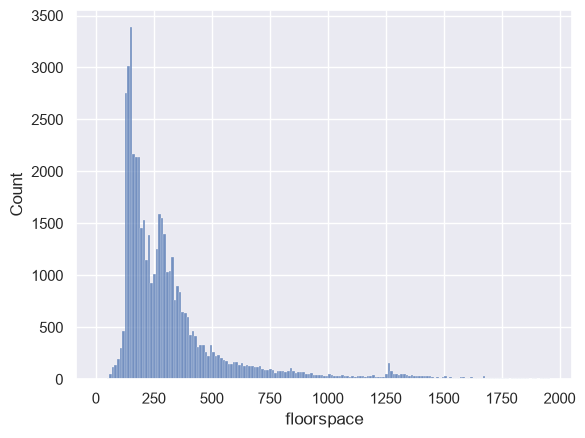

In [70]:
def observe_landed():
    res_low_fspace = buildings_gdf[
        buildings_gdf["demand_type"] == "res_low"
    ].sort_values("floorspace", ascending=False)

    res_low_fspace = res_low_fspace[
        res_low_fspace["floorspace"] < np.percentile(res_low_fspace["floorspace"], 99)
    ]
    sns.histplot(res_low_fspace["floorspace"])


observe_landed()

### Calculation

Missing Subzones:

* because this data is from 2025, there are notable subzones in the data with zero population, but end up being
counted with large quantities of buildings
  * See `res[res["work_pop_residence"] == 0].sort_values("floorspace", ascending=False)`
  * Notably, Woodlands Regional Centre, with UrbanVille @ Woodlands only starting its TOP in June of 2026
  * That is the only major one though, the others all seem to be clearing out incorrect residential outliers
  
Erroneous calculations cause by pre-calculating

* The one SZ where this happens is Ridout, where the prevalence of GCBs there sap away the residential allocation
for the couple medium-density residential buildings in the area
  * Because of this I specifically exclude Ridout from the early allocation step, 
  it gets calculated together with res_med/high

In [71]:
def calc_res(
    buildings_gdf: gpd.GeoDataFrame,
    df_employed_res_subzone: pd.DataFrame,
    subzone_gdf: gpd.GeoDataFrame,
    res_low_fspace_household_limit: float = 600,
):
    """
    Produces the following gdf of residential buildings:
    * index followings from `buildings_gdf`
        * `demand_type`
        * `geometry`
        * `floorspace`, `mp_OBJECTID`
        * `subzone_id`, `pln_area_id`, `pln_region_id`
        * `residents` - per-residential building calculated residents

    Bound by `RESIDENCE_TOTAL`

    ## Residential Processing

    Low density is processed first, then all other residential buildings to make up the remainder res capacity
    of each subzone.

    ### Low Density: `res_low`

    Some `res_low` buildings are not just single units but entire terraces, so I can't just apply the rule of
    1 household per building.

    Somewhere it was said that a GCB (these really complicate matters, ideally one would dig up the URA dataset for
    GCBAs and process accordingly but I can't be arsed) can be up to 10,000 sqft in built area, around 900 sqm.

    So let's say 600 sqm is the limit for 1 household, below which all buildings get 1 household's worth of workers;
    above it's linearly extrapolated. This limit is a default and can be defined as `res_low_fspace_household_limit`.

    ## Medium/High Densities: `res_low`, `res_med`

    follow those defined in `demandtype_coeffs` above.
    """

    RES_LOW_SZ_EXCLUSION = ["TNSZ03"]  # ridout

    buildings_gdf = buildings_gdf.copy()
    df_employed_res_subzone = df_employed_res_subzone.copy()
    subzone_gdf = subzone_gdf.copy()
    subzone_gdf["_disable_res_low_pre_calc"] = subzone_gdf.index.isin(RES_LOW_SZ_EXCLUSION)

    employed_res_subzone_gdf = gpd.GeoDataFrame(
        df_employed_res_subzone.merge(
            subzone_gdf[["geometry", "_disable_res_low_pre_calc"]],
            left_index=True,
            right_index=True,
        ),
        geometry="geometry",
        crs=subzone_gdf.crs,
    )

    b_sz_gdf = gpd.sjoin(
        buildings_gdf,
        employed_res_subzone_gdf,
        how="left",
        predicate="intersects",
    )

    # select just residential
    b_sz_res_gdf = b_sz_gdf[
        b_sz_gdf["demand_type"].isin(["res_high", "res_med", "res_low"])
    ]

    # process res_low first
    mask_res_low = (b_sz_res_gdf["demand_type"] == "res_low") & ~b_sz_res_gdf[
        "_disable_res_low_pre_calc"
    ]
    b_sz_res_gdf.loc[
        mask_res_low & (b_sz_res_gdf["floorspace"] <= res_low_fspace_household_limit),
        "residents",
    ] = WORKING_ADULTS_PER_HOUSEHOLD
    b_sz_res_gdf.loc[
        mask_res_low & (b_sz_res_gdf["floorspace"] > res_low_fspace_household_limit),
        "residents",
    ] = (
        b_sz_res_gdf["floorspace"]
        / res_low_fspace_household_limit
        * WORKING_ADULTS_PER_HOUSEHOLD
    )

    total_residents_res_low = b_sz_res_gdf["residents"].sum()
    print(f"{total_residents_res_low:.2f} low-density residential residents.")

    # now all other residential
    b_sz_res_gdf["_floorspace_mod"] = b_sz_res_gdf["floorspace"] * b_sz_res_gdf[
        "demand_type"
    ].map(demandtype_coeffs)

    grouped = b_sz_res_gdf.groupby("subzone_id", group_keys=False)

    def calc_group_residents(group: gpd.GeoDataFrame):
        mask_low = (group["demand_type"] == "res_low") & ~group[
            "_disable_res_low_pre_calc"
        ]
        residents_low = group[mask_low]["residents"].sum()
        remaining_res_total = group["work_pop_residence"] - residents_low

        group_res_remainder = group[~mask_low]

        group.loc[~mask_low, "residents"] = (
            group_res_remainder["_floorspace_mod"]
            / group_res_remainder["_floorspace_mod"].sum()
            * remaining_res_total
        ).clip(lower=0)

        return group["residents"]

    b_sz_res_gdf["residents"] = grouped.apply(calc_group_residents)

    b_sz_res_gdf = b_sz_res_gdf[
        [
            "demand_type",
            "geometry",
            "floorspace",
            "mp_OBJECTID",
            "subzone_id",
            "pln_area_id",
            "pln_region_id",
            "subzone_name",
            "residents",
        ]
    ][~b_sz_res_gdf["residents"].isna()]

    return b_sz_res_gdf


b_sz_res_gdf = calc_res(buildings_gdf, df_employed_res_subzone, subzone_gdf)

#### interesting things to observe
# b_sz_res_gdf.sort_values("residents", ascending=False)
# b_sz_res_gdf[b_sz_res_gdf["work_pop_residence"] == 0].sort_values("floorspace", ascending=False)

84148.57 low-density residential residents.


In [72]:
b_sz_res_gdf["residents"].sum()

np.float64(3019053.5181670887)

In [73]:
build_map_point_numeric_and_category(
    b_sz_res_gdf,
    numeric_col="residents",
    category_col="demand_type",
    opacity=0.2,
    radius_max=150,
)

## Workplaces

Produces the following gdf of workplace buildings:
* index followings from `buildings_gdf`
    * `demand_type`
    * `geometry`
    * `floorspace`, `mp_OBJECTID`
    * `subzone_id`, `pln_area_id`, `pln_region_id`
    * `workers` - per-workplace building calculated workers
  
**Problems**

* Sengkang ~34k workers with very few working locations
  * This causes imbalances with the agricultural areas at Seletar West; constrasted with the very low calculated densities at Seletar Airport
  * Really, this problem permeates throughout the Northeast (Punggol and Sengkang), with very little RES1C zoning to introduce those 
  1st floor retail establishments; it ends up looking incredibly sparse
  * This gets fixed to an extent by deliberately classing `subtype=commercial` in `residential` areas
* Western Catchment
* Bukit Batok
  * Because the Bukit Batok Ind Pk areas are tagged commercial (OSM tag), that makes them massive
  demand points that are wholly unrealistic. For example, WCEGA plaza gets about 11k workers, while the equally large
  Carros Centre up North gets a *much more realistic* 2+k.
  * One part of this reason is that a large proportion of BK's 40,000 workers are actually employed in the Gombak
  military areas, far above the 3000 I have estimated
    * Based on some Tablebuilder stats for industry and occupation, it seems that there are between 
    5600 and 16000 military personnel in the region
  * calculating it manually like WC *would* help to an extent... but do I want to do that?? And still, that only dampens
    it to like 85% (commercial tagging...)
  * What fixed it to an acceptable extent was pre-applying a 67% floorspace modifier to commercial buildings in B1/B2 zones


### Setup

In [74]:
df_ewarr_with_sd = df_employed_work_area_res_region

b_sz_gdf = gpd.sjoin(
    buildings_gdf,
    subzone_gdf,
    how="left",
    predicate="intersects",
)

mask_nonres = ~b_sz_gdf["demand_type"].isin(["res_high", "res_med", "res_low"])
b_sz_work_gdf = b_sz_gdf[mask_nonres]

In [75]:
build_map_places_workers = lambda gdf: build_map_point_numeric_and_category(
    gdf,
    numeric_col="workers",
    category_col="demand_type",
    opacity=0.3,
    radius_max=150,
)

### Integrate pre-defined "Special Demand" workplaces

This is where special **working** demand gets added:

* Healthcare: `sd_health_gdf`
* Military `sd_mil_gdf`
* Government agencies: `sd_gov_gdf`

Basically load them and clean up their data to fit the data format used here
and also merge with subzone-gdf

Outputs as `sd_work_gdf`.

Also subtract from existing workplace data, to subtract their totals used for later building-based distribution:

* from `df_employed_work_area_res_region` for special demand points in pln_area with exact data
* and `df_work_other_pln_area` for those in other pln_area

In [76]:
def integrate_special_demand(
    sd_health_gdf: gpd.GeoDataFrame,
    sd_mil_gdf: gpd.GeoDataFrame,
    sd_gov_gdf: gpd.GeoDataFrame,
    subzone_gdf: gpd.GeoDataFrame,
    df_ewarr: pd.DataFrame,
    df_work_other_pln_area: pd.DataFrame,
):
    df_ewarr = df_ewarr.copy()
    df_work_other_pln_area = df_work_other_pln_area.copy()

    sd_health_gdf = sd_health_gdf.copy()[
        ["healthcare_type", "workers", "geometry"]
    ].rename(columns={"healthcare_type": "demand_subtype"})
    sd_mil_gdf = sd_mil_gdf.copy()[["military_type", "workers", "geometry"]].rename(
        columns={"military_type": "demand_subtype"}
    )
    sd_gov_gdf = sd_gov_gdf.copy()[["workers", "geometry"]]

    sd_health_gdf["demand_type"] = "healthcare"
    sd_mil_gdf["demand_type"] = "military"
    sd_gov_gdf["demand_type"] = "government"

    sd_work_gdf = pd.concat([sd_health_gdf, sd_mil_gdf, sd_gov_gdf])

    sd_work_gdf = gpd.sjoin(
        sd_work_gdf,
        subzone_gdf,
        how="left",
        predicate="intersects",
    )

    sd_work_gdf = sd_work_gdf[
        [
            "demand_type",
            "demand_subtype",
            "geometry",
            "subzone_id",
            "pln_area_id",
            "pln_region_id",
            "subzone_name",
            "workers",
        ]
    ]

    ## == now update the other workplace measures, subtracting this SD data ==
    # this works for both dfs
    updatable_columns = df_work_other_pln_area.columns[-6:]

    other_pln_area_list = pln_area_gdf.index.difference(df_ewarr.index).to_list()
    sd_mask_in_other = sd_work_gdf["pln_area_id"].isin(other_pln_area_list)

    # df_work_other_pln_area
    num_sd_workers_other = sd_work_gdf[sd_mask_in_other]["workers"].sum()
    print(num_sd_workers_other)
    print(df_work_other_pln_area["work_pop_workplace"])
    sd_removed_coeff = (
        1
        - (num_sd_workers_other / df_work_other_pln_area["work_pop_workplace"]).iloc[0]
    )

    df_work_other_pln_area[updatable_columns] = df_work_other_pln_area[
        updatable_columns
    ].astype(float)
    df_work_other_pln_area.loc[:, updatable_columns] = (
        df_work_other_pln_area[updatable_columns] * sd_removed_coeff
    )

    # df_ewarr (df_employed_work_area_res_region)
    num_pln_area_sd_workers = (
        sd_work_gdf[~sd_mask_in_other].groupby("pln_area_id").agg({"workers": "sum"})
    )

    # have to do this beacuse there are pln_area with no sd workers, I think
    sd_removed_coeffs = 1 - num_pln_area_sd_workers.divide(
        df_ewarr["work_pop_workplace"], axis=0
    ).fillna(0)

    df_ewarr.loc[:, updatable_columns] = df_ewarr[updatable_columns].mul(
        sd_removed_coeffs.iloc[:, 0], axis=0
    )

    return sd_work_gdf, df_ewarr, df_work_other_pln_area


sd_work_gdf, df_ewarr, df_work_other_pln_area = integrate_special_demand(
    sd_health_gdf,
    sd_mil_gdf,
    sd_gov_gdf,
    subzone_gdf,
    df_ewarr_with_sd,
    df_work_other_pln_area,
)

10405.974842767297
45    23400
Name: work_pop_workplace, dtype: int64


In [77]:
df_work_other_pln_area

,pln_area_name,work_pop_workplace,CR,ER,NR,NER,WR
45,OTHER PLANNING AREAS OR OUTSIDE SINGAPORE,12994.025157,2554.381014,2221.200882,2443.32097,3165.211256,2609.911036


In [78]:
# a = sd_work_gdf["workers"].sum()
# b = df_ewarr["work_pop_workplace"].sum()
# c = df_work_other_pln_area["work_pop_workplace"].sum()
# df_ewarr_with_sd["work_pop_workplace"].sum() - b

### Distribute "Other" `pln_area`

Based on `df_work_other_pln_area` and `work_pln_area_no_data_list`

Produces `b_sz_work_gdf_other`

And also updates `df_employed_work_area_res_region` with the new `pln_area` that now have precise data.

HOWEVER

my immediate impression of this data is that... it does look like an overestimation. It really does not look right.
These buildings are getting way too many workers. I'll see if this has to be tweaked

Only 5 planning areas have workplace buildings to distribute to

GHS 2025's infographics doesn't show data for pln_area with < 20,000 workers, so by that metric it's fine

In [79]:
def calc_work_other_pln_area(
    b_sz_work_gdf: gpd.GeoDataFrame,
    df_work_other_pln_area: pd.DataFrame,
    work_pln_area_no_data_list: list,
):
    total_workplaces_other = df_work_other_pln_area["work_pop_workplace"].iloc[0]

    b_sz_work_gdf_other = b_sz_work_gdf[
        b_sz_work_gdf["pln_area_id"].isin(work_pln_area_no_data_list)
    ]

    b_sz_work_gdf_other["_floorspace_mod"] = b_sz_work_gdf_other[
        "floorspace"
    ] * b_sz_work_gdf_other["demand_type"].map(demandtype_coeffs)

    b_sz_work_gdf_other["workers"] = (
        b_sz_work_gdf_other["_floorspace_mod"]
        / b_sz_work_gdf_other["_floorspace_mod"].sum()
        * total_workplaces_other
    )

    b_sz_work_gdf_other = b_sz_work_gdf_other[
        [
            "demand_type",
            "geometry",
            "floorspace",
            "mp_OBJECTID",
            "subzone_id",
            "pln_area_id",
            "pln_region_id",
            "subzone_name",
            "workers",
        ]
    ]

    return b_sz_work_gdf_other


b_sz_work_gdf_other = calc_work_other_pln_area(
    b_sz_work_gdf, df_work_other_pln_area, work_pln_area_no_data_list
)
b_sz_work_gdf_other.sort_values("workers", ascending=False)

,demand_type,geometry,floorspace,mp_OBJECTID,subzone_id,pln_area_id,pln_region_id,subzone_name,workers
91783,office,POINT (27827.065 31565.4),55921.781250,681647.0,RVSZ02,RV,CR,PATERSON,986.345972
91784,commercial,POINT (27827.065 31565.4),37281.187500,681647.0,RVSZ02,RV,CR,PATERSON,597.785437
417,commercial,POINT (28624.058 30546.002),19456.449219,641988.0,RVSZ05,RV,CR,INSTITUTION HILL,311.974558
89623,ind_low,POINT (16095.687 46545.925),59795.550781,620935.0,LKSZ01,LK,NR,LIM CHU KANG,239.698035
97710,office,POINT (31182.206 29518.181),11622.816406,604459.0,MSSZ01,MS,CR,MARINA SOUTH,205.002736
...,...,...,...,...,...,...,...,...,...
92083,commercial,POINT (28680.322 31230.267),35.080509,688997.0,RVSZ04,RV,CR,OXLEY,0.562499
87851,commercial,POINT (17434.911 37942.816),31.662188,617071.0,THSZ03,TH,WR,PARK,0.507688
89494,ind_low,POINT (14165.822 47104.804),122.095993,631135.0,LKSZ01,LK,NR,LIM CHU KANG,0.489437
87879,commercial,POINT (17323.828 37944.71),30.115368,617071.0,THSZ03,TH,WR,PARK,0.482885


In [80]:
# build_map_places_workers(b_sz_work_gdf_other)

### Distribute main `pln_area`s

Excluding Western Catchment `WC`

In [81]:
def calc_work(
    b_sz_gdf: gpd.GeoDataFrame,
    df_ewarr: pd.DataFrame,
    subzone_gdf: gpd.GeoDataFrame,
    pln_area_excluded: list[str] = ["WC"],
):
    """
    Produces the following gdf of workplace buildings:
    * index followings from `buildings_gdf`
        * `demand_type`
        * `geometry`
        * `floorspace`, `mp_OBJECTID`
        * `subzone_id`, `pln_area_id`, `pln_region_id`
        * `workers` - per-workplace building calculated workers

    Bound by `WORKPLACE_TOTAL`

    ## Distribute workplaces to other PLN_AREA

    With their residence regions being in `df_work_other_pln_area`, and
    the list of pln_area that need distribution being work_pln_area_no_data_list

    ## Workplace Processing

    Generally allow those defined in `demandtype_coeffs` above.
    """
    b_sz_gdf = b_sz_gdf.copy()
    df_ewarr = df_ewarr.copy()
    subzone_gdf = subzone_gdf.copy()

    b_sz_gdf = b_sz_gdf[~b_sz_gdf["pln_area_id"].isin(pln_area_excluded)]

    b_sz_gdf = b_sz_gdf.merge(
        df_ewarr["work_pop_workplace"], left_on="pln_area_id", right_index=True
    )

    mask_nonres = ~b_sz_gdf["demand_type"].isin(["res_high", "res_med", "res_low"])
    b_sz_work_gdf = b_sz_gdf[mask_nonres]

    b_sz_work_gdf["_floorspace_mod"] = b_sz_work_gdf["floorspace"] * b_sz_work_gdf[
        "demand_type"
    ].map(demandtype_coeffs)

    # return b_sz_work_gdf["_floorspace_mod"]

    grouped = b_sz_work_gdf.groupby("pln_area_id", group_keys=False)

    def calc_group_workers(group: gpd.GeoDataFrame):
        group["workers"] = (
            group["_floorspace_mod"]
            / group["_floorspace_mod"].sum()
            * group["work_pop_workplace"]
        )
        # .clip(0)

        return group["workers"]

    b_sz_work_gdf["workers"] = grouped.apply(calc_group_workers)

    b_sz_work_gdf = b_sz_work_gdf[
        [
            "demand_type",
            "geometry",
            "floorspace",
            # "_floorspace_mod",
            "mp_OBJECTID",
            "subzone_id",
            "pln_area_id",
            "pln_region_id",
            "subzone_name",
            "workers",
        ]
    ][~b_sz_work_gdf["workers"].isna()]

    return b_sz_work_gdf


b_sz_work_gdf_main = calc_work(
    b_sz_gdf=b_sz_gdf,
    df_ewarr=df_ewarr,
    subzone_gdf=subzone_gdf,
    pln_area_excluded=["WC"],
)

#### interesting things to observe
b_sz_work_gdf_main.sort_values("workers", ascending=False)

,demand_type,geometry,floorspace,mp_OBJECTID,subzone_id,pln_area_id,pln_region_id,subzone_name,workers
92506,commercial,POINT (29593.506 28900.521),452580.468750,600806.0,DTSZ08,DT,CR,CECIL,22590.166172
686,commercial,POINT (45408.726 38032.184),245953.953125,688315.0,CHSZ03,CH,ER,CHANGI AIRPORT,19687.475250
428,commercial,POINT (30148.917 28885.605),348148.031250,599097.0,DTSZ11,DT,CR,CENTRAL SUBZONE,17377.510567
94534,commercial,POINT (29949.836 29513.227),318726.312500,649895.0,DTSZ05,DT,CR,RAFFLES PLACE,15908.950695
95967,office,POINT (30353.378 29047.075),238845.875000,593338.0,DTSZ11,DT,CR,CENTRAL SUBZONE,13113.965838
...,...,...,...,...,...,...,...,...,...
106687,commercial,POINT (28209.598 44166.501),3.416746,593536.0,YSSZ04,YS,NR,YISHUN SOUTH,0.151050
85389,ind_low,POINT (13400.201 32348.113),95.655159,606269.0,BLSZ03,BL,WR,SAMULUN,0.125395
81024,ind_low,POINT (6568.43 29225.36),51.098656,605295.0,TSSZ06,TS,WR,TUAS VIEW EXTENSION,0.105462
81025,ind_low,POINT (6565.296 29253.226),33.950424,605295.0,TSSZ06,TS,WR,TUAS VIEW EXTENSION,0.070070


In [82]:
# build_map_places_workers(b_sz_work_gdf_main)

### Deal with Western Catchment `WC`

`WC` has about 32k total workers in the official stats, military by my *rather abstracted* calculations has ~30+k... 
sooo I have to calculate the non-military demand in `WC` separately.

See `sd_work_gdf[sd_work_gdf["pln_area_id"] == "WC"]["workers"].sum()`

Do this using floorspace ratios from the already-computed `b_sz_work_gdf`

In [83]:
def compute_western_catchment(
    b_sz_gdf: gpd.GeoDataFrame,
    b_sz_work_gdf_main: gpd.GeoDataFrame,
):
    """
    I am far too lazy to do any sort of proper regression

    so just making use of a "workers per floorspace" average shall suffice
    """
    b_sz_gdf = b_sz_gdf.copy()
    b_sz_work_gdf_main = b_sz_work_gdf_main.copy()
    mask_nonres = ~b_sz_gdf["demand_type"].isin(["res_high", "res_med", "res_low"])
    b_sz_wc_gdf = b_sz_gdf[mask_nonres & (b_sz_gdf["pln_area_id"] == "WC")]

    b_sz_work_gdf_main["_workers_per_fs"] = (
        b_sz_work_gdf_main["workers"] / b_sz_work_gdf_main["floorspace"]
    )

    dmdtype_wpfs_dict = (
        b_sz_work_gdf_main.groupby("demand_type")
        .agg({"_workers_per_fs": "mean"})
        .to_dict()["_workers_per_fs"]
    )

    b_sz_wc_gdf["_workers_per_fs"] = b_sz_wc_gdf["demand_type"].map(dmdtype_wpfs_dict)
    b_sz_wc_gdf["workers"] = b_sz_wc_gdf["floorspace"] * b_sz_wc_gdf["_workers_per_fs"]

    num_workers_wc = b_sz_wc_gdf["workers"].sum()

    print(f"{num_workers_wc:.2f} workers in Western Catchment (WC)")

    # finally select the right cols
    b_sz_wc_gdf = b_sz_wc_gdf[
        [
            "demand_type",
            "geometry",
            "floorspace",
            "mp_OBJECTID",
            "subzone_id",
            "pln_area_id",
            "pln_region_id",
            "subzone_name",
            "workers",
        ]
    ]

    return b_sz_wc_gdf


b_sz_work_gdf_wc = compute_western_catchment(b_sz_gdf, b_sz_work_gdf_main)

5748.17 workers in Western Catchment (WC)


### Finally, Combine all Workplaces

In [84]:
def combine_all_workplaces(work_gdf_list=list[gpd.GeoDataFrame]):

    combined = pd.concat(work_gdf_list)
    combined = combined[
        [
            "demand_type",
            "demand_subtype",
            "geometry",
            "subzone_id",
            "pln_area_id",
            "pln_region_id",
            "workers",
            # "floorspace", 
            # "_floorspace_mod",
        ]
    ]

    b_sz_work_gdf = gpd.GeoDataFrame(
        combined, geometry=combined["geometry"], crs=work_gdf_list[0].crs
    )

    return b_sz_work_gdf


b_sz_work_gdf = combine_all_workplaces(
    [
        b_sz_work_gdf_main,
        b_sz_work_gdf_other,
        b_sz_work_gdf_wc,
        sd_work_gdf,
    ]
)

b_sz_work_gdf

,demand_type,demand_subtype,geometry,subzone_id,pln_area_id,pln_region_id,workers
0,commercial,NaN,POINT (5984.509 36097.087),TSSZ02,TS,WR,62.963365
9,ind_med,NaN,POINT (13414.6 37818.933),JWSZ01,JW,WR,865.855611
10,ind_med,NaN,POINT (13479.802 37685.931),JWSZ01,JW,WR,341.758488
11,ind_med,NaN,POINT (13557.292 37769.762),JWSZ01,JW,WR,281.396257
12,ind_med,NaN,POINT (13579.418 37594.076),JWSZ01,JW,WR,339.978302
...,...,...,...,...,...,...,...
11,government,NaN,POINT (29815.21 30362.486),DTSZ02,DT,CR,544.000000
12,government,NaN,POINT (29218.467 29985.312),SRSZ02,SR,CR,2325.000000
13,government,NaN,POINT (29391.641 29031.163),DTSZ07,DT,CR,403.000000
14,government,NaN,POINT (29815.21 30362.486),DTSZ02,DT,CR,1113.000000


Make a new df_ewarr that includes sd and other worker demand

In [85]:
def update_df_ewarr(
    df_ewarr_with_sd: pd.DataFrame,
    b_sz_work_gdf_other: gpd.GeoDataFrame,
    sd_work_gdf: gpd.GeoDataFrame,
    b_sz_work_gdf_wc: gpd.GeoDataFrame,
):
    """
    Updates `df_ewarr_with_sd` using the new building workplaces in `b_sz_work_gdf_other`
    and those in `sd_work_gdf`; as well as updating WC

    This is to update `df_ewarr_with_sd` for future O/D processing.

    `df_ewarr_with_sd` is used as that already includes SD demand in its `pln_area`s, with `df_ewarr`
    having already had that removed for building distribution purposes.
    So `b_sz_work_gdf_other` and `sd_work_gdf` only add to the *other* `pln_area`s.

    To add residence pln_region for Other,
    take residence pln_region distribution ratios from nearest `pln_area`s.
    The mean ratios of all adjacent `pln_area`s is then used.
    """

    current_pln_areas = df_ewarr_with_sd.index.tolist()
    updatable_columns = df_ewarr_with_sd.columns[-6:]

    df_ewarr_with_sd = df_ewarr_with_sd.copy()
    gdf_other = b_sz_work_gdf_other.copy()
    gdf_sd = sd_work_gdf[~sd_work_gdf["pln_area_id"].isin(current_pln_areas)]
    gdf_wc = b_sz_work_gdf_wc.copy()

    # handle wc first
    update_coeff = (
        gdf_wc["workers"].sum()
        + sd_work_gdf[sd_work_gdf["pln_area_id"] == "WC"]["workers"].sum()
    ) / df_ewarr_with_sd.loc["WC"]["work_pop_workplace"]
    print(f"WC workers update coefficient: {update_coeff}")
    df_ewarr_with_sd.loc[df_ewarr_with_sd.index == "WC", updatable_columns] = (
        df_ewarr_with_sd[df_ewarr_with_sd.index == "WC"][updatable_columns]
        * update_coeff
    )
    print(df_ewarr_with_sd["work_pop_workplace"].sum())

    # now the others
    gdf_all_other = pd.concat([gdf_other, gdf_sd])
    pln_area_worker_sum = gdf_all_other.groupby("pln_area_id").agg({"workers": "sum"})
    print(pln_area_worker_sum["workers"].sum())

    # take residence pln_region distribution ratios from nearest pln_area
    ewarr_gdf = df_ewarr_with_sd.merge(
        pln_area_gdf["geometry"], left_index=True, right_index=True
    )
    pln_area_worker_sum_gdf = pln_area_worker_sum.merge(
        pln_area_gdf["geometry"], left_index=True, right_index=True
    )
    pln_area_worker_sum_gdf = gpd.GeoDataFrame(pln_area_worker_sum_gdf, crs=gdf_sd.crs)
    ewarr_gdf = gpd.GeoDataFrame(ewarr_gdf, crs=gdf_sd.crs)

    nearests = pln_area_worker_sum_gdf.sjoin_nearest(
        ewarr_gdf, how="left", distance_col="distance"
    )
    nearests.index = nearests.index.rename("pln_area_id")
    nearests = nearests[pln_region_gdf.index].groupby("pln_area_id").agg("mean")
    nearests = nearests.div(nearests.sum(axis=1), axis=0)

    nearests = nearests.multiply(pln_area_worker_sum_gdf["workers"], axis=0)

    df_ewarr_other = pd.concat(
        [pln_area_worker_sum_gdf.drop(columns="geometry"), nearests], axis=1
    )
    df_ewarr_other = df_ewarr_other.merge(
        pln_area_gdf[["pln_region_id", "pln_area_name"]],
        left_index=True,
        right_index=True,
    )
    df_ewarr_other = df_ewarr_other.rename(columns={"workers": "work_pop_workplace"})

    return pd.concat([df_ewarr_with_sd, df_ewarr_other])


df_ewarr_all = update_df_ewarr(
    df_ewarr_with_sd,
    b_sz_work_gdf_other,
    sd_work_gdf,
    b_sz_work_gdf_wc,
)

WC workers update coefficient: 0.8687127980731072
2990068.239225043
23400.0


### Visualize

In [86]:
df_ewarr_with_sd.loc[["SE", "SL"]]

,pln_region_id,pln_area_name,work_pop_workplace,CR,ER,WR,NR,NER
pln_area_id,,,,,,,,
SE,NER,SENGKANG,34495.239514,2184.424838,3480.523111,1597.819584,2499.972229,24732.499752
SL,NER,SELETAR,9215.945300,873.769935,2465.370537,726.281629,1911.743469,3238.779729


In [87]:
build_map_places_workers(b_sz_work_gdf)

# Point Aggregation

This section is mostly LLM-generated. I have checked through it.

In [88]:

b_sz_res_gdf

,demand_type,geometry,floorspace,mp_OBJECTID,subzone_id,pln_area_id,pln_region_id,subzone_name,residents
7,res_med,POINT (13387.557 36759.105),10922.994141,620449.0,JWSZ08,JW,WR,YUNNAN,167.858580
8,res_med,POINT (13344.034 36813.811),9196.934570,620449.0,JWSZ08,JW,WR,YUNNAN,141.333444
207,res_low,POINT (21704.902 32205.616),419.295471,693821.0,QTSZ10,QT,CR,DOVER,1.584292
208,res_low,POINT (21732.961 32162.824),387.960968,693821.0,QTSZ10,QT,CR,DOVER,1.584292
209,res_low,POINT (21756.709 32072.733),300.467621,693821.0,QTSZ10,QT,CR,DOVER,1.584292
...,...,...,...,...,...,...,...,...,...
108302,res_high,POINT (45167.289 41219.927),5476.282227,598188.0,CHSZ01,CH,ER,CHANGI POINT,36.766714
108306,res_high,POINT (45232.768 41260.317),2730.743896,598188.0,CHSZ01,CH,ER,CHANGI POINT,18.333694
108308,res_high,POINT (45232.768 41260.317),2619.721191,598188.0,CHSZ01,CH,ER,CHANGI POINT,17.588308
108310,res_high,POINT (45202.119 41146.03),8554.399414,598188.0,CHSZ01,CH,ER,CHANGI POINT,57.432606


In [89]:
# first combine res and work
bp_gdf = pd.concat([b_sz_res_gdf, b_sz_work_gdf])[
    [
        "demand_type",
        "demand_subtype",
        "subzone_id",
        "pln_area_id",
        "pln_region_id",
        "residents",
        "workers",
        "geometry",
    ]
]
bp_gdf[["residents", "workers"]] = bp_gdf[["residents", "workers"]].fillna(0)

In [90]:
gdf = bp_gdf.copy()
res_mean = gdf[bp_gdf["residents"] > 0]["residents"].mean()
work_mean = gdf[bp_gdf["workers"] > 0]["workers"].mean()

gdf["weight"] = np.sqrt(gdf["residents"] / res_mean) + np.sqrt(
    gdf["workers"] / work_mean
)

rng = np.random.default_rng(0)

mass-biased weighted random priority

seed-selection, using a spatial-hash implementation

In [91]:
def weighted_inhibition_sample(gdf, score_column, min_distance, random_seed=0):
    def cell_key(x, y, cell_size):
        return (
            int(np.floor(x / cell_size)),
            int(np.floor(y / cell_size))
        )

    rng = np.random.default_rng(random_seed)

    xy = np.column_stack([gdf.geometry.x.to_numpy(), gdf.geometry.y.to_numpy()])

    score = np.maximum(gdf[score_column].to_numpy(dtype=float), 1e-9)

    priority = rng.exponential(scale=1 / score)

    order = np.argsort(priority)

    occupied = {}
    accepted = []

    for idx in order:
        x, y = xy[idx]
        cx, cy = cell_key(x, y, min_distance)

        nearby_indices = []

        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                nearby_indices.extend(occupied.get((cx + dx, cy + dy), []))

        blocked = False

        for other_idx in nearby_indices:
            distance = np.hypot(x - xy[other_idx, 0], y - xy[other_idx, 1])

            if distance < min_distance:
                blocked = True
                break

        if not blocked:
            accepted.append(idx)
            occupied.setdefault((cx, cy), []).append(idx)

    return np.asarray(accepted, dtype=int)

seed_indices = weighted_inhibition_sample(
    gdf, score_column="weight", min_distance=200, random_seed=0
)
print(len(seed_indices))

4499


assign each building to its nearest seed

In [92]:
source_xy = np.column_stack([gdf.geometry.x.to_numpy(), gdf.geometry.y.to_numpy()])

seed_xy = source_xy[seed_indices]

seed_tree = KDTree(seed_xy)

distances, nearest_seed = seed_tree.query(source_xy)

gdf["cluster_id"] = nearest_seed
gdf["distance_to_seed"] = distances

In [93]:
cluster_values = gdf.groupby("cluster_id", as_index=False).agg(
    residents=("residents", "sum"),
    workers=("workers", "sum"),
    source_count=("cluster_id", "size"),
    max_source_distance=("distance_to_seed", "max"),
    weight=("weight", "sum")
)

def weighted_point_np(xs, ys, weights):
    return Point(np.average(xs, weights=weights), np.average(ys, weights=weights))

def weighted_point(group, weight_column):
    weights = group[weight_column].to_numpy(dtype=float)
    xs = group.geometry.x.to_numpy()
    ys = group.geometry.y.to_numpy()

    if weights.sum() <= 0:
        return group.geometry.iloc[0]

    return weighted_point_np(xs, ys, weights)


cluster_geometry = (
    gdf.groupby("cluster_id")
    .apply(lambda group: weighted_point(group, "weight"))
    .rename("geometry")
    .reset_index()
)

demand_gdf = cluster_values.merge(cluster_geometry, on="cluster_id")
demand_gdf = gpd.GeoDataFrame(demand_gdf, geometry="geometry", crs=gdf.crs)
demand_gdf = demand_gdf[(demand_gdf["workers"] > 0) | (demand_gdf["residents"] > 0)].drop(columns="cluster_id")

In [94]:
build_map_point_numeric_and_category(
    demand_gdf,
    numeric_col="residents",
)

## Deal with Undersized Values

Each final point should have at least 50 residents OR workers

Just merge with the nearest point

In [95]:
MINIMUM_SIZE = 50

In [96]:
is_undersized = (
    np.maximum(
        demand_gdf["workers"] / MINIMUM_SIZE,
        demand_gdf["residents"] / MINIMUM_SIZE,
    )
    < 1
)

print(
    f"There are {is_undersized.sum()} points with less than {MINIMUM_SIZE} residents or workers."
)

There are 267 points with less than 50 residents or workers.


In [97]:
demand_gdf_is_undersized = demand_gdf[is_undersized]
demand_gdf_is_not_undersized = demand_gdf[~is_undersized]

In [98]:
matches = gpd.sjoin_nearest(
    demand_gdf_is_undersized,
    demand_gdf_is_not_undersized,
    how="left",
    distance_col="distance",
    lsuffix="x",
    rsuffix="y",
)

In [99]:
demand_gdf_to_merge = demand_gdf[
    demand_gdf.index.isin(matches.index) | demand_gdf.index.isin(matches["index_y"])
]

demand_gdf_to_merge.loc[
    demand_gdf_to_merge.index.isin(matches.index), "merge_index"
] = matches["index_y"]
demand_gdf_to_merge.loc[
    demand_gdf_to_merge.index.isin(matches["index_y"]), "merge_index"
] = demand_gdf_to_merge[
    demand_gdf_to_merge.index.isin(matches["index_y"])
].index
demand_gdf_to_merge["merge_index"] = demand_gdf_to_merge["merge_index"].astype(int)

In [100]:
merged = demand_gdf_to_merge.groupby("merge_index").agg({
    "residents": "sum",
    "workers": "sum",
    "source_count": "sum",
    "max_source_distance": "max",
    "weight": "sum",
})
merged = merged.set_geometry(
    demand_gdf_to_merge.groupby("merge_index")
    .apply(lambda group: weighted_point(group, "weight"))
    .rename("geometry")
)

demand_gdf = demand_gdf[
    ~(
        demand_gdf.index.isin(demand_gdf_to_merge.index)
        & ~demand_gdf.index.isin(merged.index)
    )
]
demand_gdf.loc[merged.index] = merged

print(demand_gdf.columns)

Index(['residents', 'workers', 'source_count', 'max_source_distance', 'weight',
       'geometry'],
      dtype='str')


In [101]:
build_map_point_numeric_and_category(
    demand_gdf,
    numeric_col="workers",
)

# Export inputs for distance-decay distribution
Run through this section, then open [4_population_distance_decay.ipynb](4_population_distance_decay.ipynb). The legacy OD workflow below is retained for comparison.

In [ ]:
if ALLOW_EXPORT:
    os.makedirs(data_filepaths.path_data_intermediate, exist_ok=True)
    
    demand_gdf.to_parquet(data_filepaths.AGGREGATED_DEMAND_POINTS)
    df_ewarr_all.to_parquet(data_filepaths.WORKPLACE_RESIDENCE_OD)
    print(f"Exported {len(demand_gdf)} aggregated demand points and {len(df_ewarr_all)} OD areas.")

Exported 4231 aggregated demand points and 52 OD areas.


In [ ]:
assert False, "Do not continue"

# OD

In [114]:
from scipy.spatial import cKDTree
from scipy.optimize import linprog
from scipy.sparse import coo_matrix

## Test Simple Version + Export

Random residence<->job allocation

Just a workflow test

In [ ]:
temp_demand_gdf = demand_gdf.copy()

In [116]:
MIN_UNIT_SIZE = MINIMUM_SIZE
# MAX_UNIT_SIZE = 200

In [117]:
# temp_demand_gdf["workers"] = (
#     temp_demand_gdf["workers"]
#     / temp_demand_gdf["workers"].sum()
#     * temp_demand_gdf["residents"].sum()
# )

In [118]:
# TODO FIX
# now remove those that aren't in any VALID region (this is typically erroneous ones over the sea, happens during the aggregation, it really needs fixing)
temp_demand_gdf = temp_demand_gdf[
    temp_demand_gdf.index.isin(
        temp_demand_gdf.sjoin(
            pln_region_gdf[["geometry"]],
            predicate="intersects",
        ).index
    )
]

In [119]:
# add "p_" to indexes
temp_demand_gdf = temp_demand_gdf.add_prefix("p_", axis="index")

temp_demand_gdf["residents_unit_count"] = (
    (temp_demand_gdf["residents"] / MIN_UNIT_SIZE).round().astype(int)
)
temp_demand_gdf["workers_unit_count"] = (
    (temp_demand_gdf["workers"] / MIN_UNIT_SIZE).round().astype(int)
)
num_res_pops = temp_demand_gdf["residents_unit_count"].sum()
num_work_pops = temp_demand_gdf["workers_unit_count"].sum()

In [120]:
print(
    f"Initial pop counts: {temp_demand_gdf["residents"].sum()} residents and {temp_demand_gdf["workers"].sum()} workers"
    f"\nMin pop unit size: {MIN_UNIT_SIZE}"
    f"\nTotal number of pop: {num_res_pops} residents; {num_work_pops} workers"
    f"\nNumber of empty pops: {((temp_demand_gdf["residents_unit_count"] == 0) & (temp_demand_gdf["workers_unit_count"] == 0)).sum()}"
)

Initial pop counts: 3018853.5891321613 residents and 3013468.239225043 workers
Min pop unit size: 50
Total number of pop: 60344 residents; 60263 workers
Number of empty pops: 0


In [121]:
work_pops_gdf = (
    temp_demand_gdf["geometry"]
    .loc[temp_demand_gdf.index.repeat(temp_demand_gdf["workers_unit_count"])]
    .reset_index()
    .rename(columns={"index": "point_id"})
)
res_pops_gdf = (
    temp_demand_gdf["geometry"]
    .loc[temp_demand_gdf.index.repeat(temp_demand_gdf["residents_unit_count"])]
    .reset_index()
    .rename(columns={"index": "point_id"})
)

for whichever has more pops, randomly remove from it

In [122]:
if num_work_pops > num_res_pops:
    delta = num_work_pops - num_res_pops
    work_pops_gdf = work_pops_gdf.drop(
        work_pops_gdf.sample(n=delta, random_state=0).index
    ).reset_index(drop=True)
elif num_res_pops > num_work_pops:
    delta = num_res_pops - num_work_pops
    res_pops_gdf = res_pops_gdf.drop(
        res_pops_gdf.sample(n=delta, random_state=0).index
    ).reset_index(drop=True)

In [123]:
import src.utils.point_dist as point_dist


def distribute_random(
    res_pops_gdf: gpd.GeoDataFrame,
    work_pops_gdf: gpd.GeoDataFrame,
    pop_size: float = 50,
) -> gpd.GeoDataFrame:
    """
    Each x_pops_gdf has `point_id` (string), `geometry` (POINT)

    Return GDF has:
    * `pop_id` (string)
    * `res_point_id`, `res_geometry`, `work_point_id`, `size`
    """

    rng = np.random.default_rng(0)

    # RANDOMLY DISTIRBUTE WORKPLACE points
    res_pops_gdf["work_point_id"] = shuffle_df(work_pops_gdf["point_id"], rng=rng)

    pops_gdf = res_pops_gdf.rename(
        columns={"point_id": "res_point_id", "geometry": "res_geometry"}
    ).reset_index(names="pop_id")

    # now that all pops are set in stone, make pop ids strings
    pops_gdf["pop_id"] = pops_gdf["pop_id"].astype(str)

    pops_gdf["size"] = pop_size
    return pops_gdf


def distribute_od_ewarr(
    res_pops_gdf: gpd.GeoDataFrame,
    work_pops_gdf: gpd.GeoDataFrame,
    df_ewarr: pd.DataFrame,
    pln_area_gdf: gpd.GeoDataFrame,
    pln_region_gdf: gpd.GeoDataFrame,
    pop_size: float = 50,
) -> gpd.GeoDataFrame:
    """
    Each x_pops_gdf has `point_id` (string), `geometry` (POINT)

    How this is currently done:
    * df_ewarr has to be converted to exact numbers of points
        * Done through proportional of points to row(pln_area)-normalized weights
        * Becomes a "non-negative integer matrix allocation problem". This was outsourced to an LLM
    * Then,
        * Work points are shuffled
        * Work points then partitioned based on the prior calculated counts, and assigned to pln_region
        * Then assigned to the res points


    Return:
        gpd.GeoDataFrame with Columns:
        * `pop_id` (string)
        * `res_point_id`, `res_geometry`, `work_point_id`, `size`
    """

    assert res_pops_gdf.crs == work_pops_gdf.crs
    res_pops_gdf = res_pops_gdf.copy()
    work_pops_gdf = work_pops_gdf.copy()
    df_ewarr = df_ewarr.copy()

    rng = np.random.default_rng(0)

    REGION_COLS = ["CR", "ER", "WR", "NR", "NER"]

    work_pops_pln_area = work_pops_gdf.sjoin(
        pln_area_gdf[["geometry"]], predicate="intersects"
    )
    work_counts_pln_area = work_pops_pln_area.groupby("pln_area_id").agg(
        count=("geometry", "count")
    )["count"]

    res_pops_pln_region = res_pops_gdf.sjoin(
        pln_region_gdf[["geometry"]], predicate="intersects"
    )
    res_counts_pln_region = res_pops_pln_region.groupby("pln_region_id").agg(
        count=("geometry", "count")
    )["count"]
    assert (
        work_counts_pln_area.sum() == res_counts_pln_region.sum()
    ), "Diff number of work and res points"

    # normalize each row
    df_ewarr[REGION_COLS] = df_ewarr[REGION_COLS].div(
        df_ewarr[REGION_COLS].sum(axis=1), axis=0
    )

    # this uses milp, it's an optimization problem, I have no clue how it works :)
    # but it does, and that's all that matters
    point_allocation = point_dist.integer_proportional_allocation(
        weights=df_ewarr[REGION_COLS],
        row_totals=work_counts_pln_area,
        col_totals=res_counts_pln_region,
    )

    # shuffle both
    work_pops_pln_area = shuffle_df(work_pops_pln_area, rng=rng)
    res_pops_pln_region = shuffle_df(res_pops_pln_region, rng=rng)

    for pln_area_id in point_allocation.index.to_list():
        region_counts = point_allocation.loc[pln_area_id]
        repeated_region_id = region_counts.index.repeat(region_counts)

        work_pop_mask = work_pops_pln_area["pln_area_id"] == pln_area_id

        assert len(work_pops_pln_area[work_pop_mask]) == len(
            repeated_region_id
        ), "Number of repeated region ids != number of work pops to insert into"

        work_pops_pln_area.loc[work_pop_mask, "res_pln_region_id"] = repeated_region_id

    work_pops_pln_area = work_pops_pln_area.sort_values(
        "res_pln_region_id"
    ).reset_index(drop=True)
    res_pops_pln_region = res_pops_pln_region.sort_values("pln_region_id").reset_index(
        drop=True
    )

    pops_gdf = (
        res_pops_pln_region[["point_id", "geometry"]]
        .rename(columns={"point_id": "res_point_id", "geometry": "res_geometry"})
        .merge(
            work_pops_pln_area[["point_id"]].rename(
                columns={"point_id": "work_point_id"}
            ),
            left_index=True,
            right_index=True,
        )
    )

    # finally clean up pops_gdf for export(this should be somewhere else)
    pops_gdf = pops_gdf.reset_index(names="pop_id")
    pops_gdf["pop_id"] = pops_gdf["pop_id"].astype(str)

    pops_gdf["size"] = pop_size

    return pops_gdf

distribute_od_ewarr(
    res_pops_gdf, work_pops_gdf, df_ewarr_all, pln_area_gdf, pln_region_gdf
)

,pop_id,res_point_id,res_geometry,work_point_id,size
0,0,p_691,POINT (26170.334 30271.759),p_2389,50
1,1,p_1204,POINT (34012.931 34717.918),p_4029,50
2,2,p_4394,POINT (30989.757 31864.332),p_3032,50
3,3,p_1850,POINT (23897.547 32228.973),p_168,50
4,4,p_2040,POINT (31241.957 31520.311),p_850,50
...,...,...,...,...,...
60258,60258,p_121,POINT (18123.457 41029.793),p_3475,50
60259,60259,p_1117,POINT (20324.21 33004.7),p_3940,50
60260,60260,p_2648,POINT (20786.96 41048.735),p_2509,50
60261,60261,p_1912,POINT (20303.683 32716.351),p_2770,50


In [124]:
# random
# pops_gdf = distribute_random(res_pops_gdf, work_pops_gdf, pop_size=50)

# random using df_ewarr
pops_gdf = distribute_od_ewarr(
    res_pops_gdf, work_pops_gdf, df_ewarr_all, pln_area_gdf, pln_region_gdf
)

In [125]:
pops_gdf

,pop_id,res_point_id,res_geometry,work_point_id,size
0,0,p_691,POINT (26170.334 30271.759),p_2389,50
1,1,p_1204,POINT (34012.931 34717.918),p_4029,50
2,2,p_4394,POINT (30989.757 31864.332),p_3032,50
3,3,p_1850,POINT (23897.547 32228.973),p_168,50
4,4,p_2040,POINT (31241.957 31520.311),p_850,50
...,...,...,...,...,...
60258,60258,p_121,POINT (18123.457 41029.793),p_3475,50
60259,60259,p_1117,POINT (20324.21 33004.7),p_3940,50
60260,60260,p_2648,POINT (20786.96 41048.735),p_2509,50
60261,60261,p_1912,POINT (20303.683 32716.351),p_2770,50


In [126]:
# TESTING ONLY TESTING ONLY
# pops_gdf = pops_gdf.iloc[:1]
pops_gdf

,pop_id,res_point_id,res_geometry,work_point_id,size
0,0,p_691,POINT (26170.334 30271.759),p_2389,50
1,1,p_1204,POINT (34012.931 34717.918),p_4029,50
2,2,p_4394,POINT (30989.757 31864.332),p_3032,50
3,3,p_1850,POINT (23897.547 32228.973),p_168,50
4,4,p_2040,POINT (31241.957 31520.311),p_850,50
...,...,...,...,...,...
60258,60258,p_121,POINT (18123.457 41029.793),p_3475,50
60259,60259,p_1117,POINT (20324.21 33004.7),p_3940,50
60260,60260,p_2648,POINT (20786.96 41048.735),p_2509,50
60261,60261,p_1912,POINT (20303.683 32716.351),p_2770,50


### TODO: Some fix for same res/work pops

Currently the fix is to remove them:

About 8 show up at the moment

I did suspect that this was causing a rendering bug, but no, it's not this that's a problem

Later attempts should just **prevent this from happening entirely.**

In [127]:
same_res_work_pops = (pops_gdf["res_point_id"] == pops_gdf["work_point_id"])
print(f"There are {len(same_res_work_pops)} pops with the same residence and workplace")

There are 60263 pops with the same residence and workplace


In [128]:
# grouping
grouped_pops = pops_gdf.groupby(["res_point_id", "work_point_id"], as_index=False).agg(
    {"res_geometry": "first", "size": "sum"}
)
grouped_pops["size"].value_counts()

# it's here if you want to check, but it's too little to matter atm

size
50     55650
100     2059
150      132
200       17
250        5
300        1
Name: count, dtype: int64

### Continue with processing

In [129]:
points_gdf = temp_demand_gdf.copy()
points_gdf[["res_pop_ids", "residents"]] = (
    pops_gdf.reset_index(drop=True)
    .groupby("res_point_id")
    .agg(res_pop_ids=("pop_id", list), res_size=("size", "sum"))
    # .map(lambda x: [] if pd.isna(x) else x)  # fillna([]) no workey :(
)

points_gdf[["work_pop_ids", "workers"]] = (
    pops_gdf.reset_index(drop=True)
    .groupby("work_point_id")
    .agg(work_pop_ids=("pop_id", list), work_size=("size", "sum"))
    # .map(lambda x: [] if pd.isna(x) else x)  # fillna([]) no workey :(
)

points_gdf[["residents", "workers"]] = points_gdf[["residents", "workers"]].fillna(0)

In [130]:
# both NaN means points would have been dropped in the earlier drop-to-equalize step
points_gdf = points_gdf[
    ~(points_gdf["res_pop_ids"].isna() & points_gdf["work_pop_ids"].isna())
]


points_gdf["pop_ids"] = points_gdf.apply(
    lambda r: (r["res_pop_ids"] if isinstance(r["res_pop_ids"], list) else [])
    + (r["work_pop_ids"] if isinstance(r["work_pop_ids"], list) else []),
    axis=1,
)

points_gdf = points_gdf[
    ["residents", "workers", "geometry", "pop_ids"]
]

### Handle `pops_gdf` Travel Times (in seconds) and Distances

In [131]:
DRIVING_SPEED = 40 / 3.6 # 30 kph

In [132]:
pops_gdf

,pop_id,res_point_id,res_geometry,work_point_id,size
0,0,p_691,POINT (26170.334 30271.759),p_2389,50
1,1,p_1204,POINT (34012.931 34717.918),p_4029,50
2,2,p_4394,POINT (30989.757 31864.332),p_3032,50
3,3,p_1850,POINT (23897.547 32228.973),p_168,50
4,4,p_2040,POINT (31241.957 31520.311),p_850,50
...,...,...,...,...,...
60258,60258,p_121,POINT (18123.457 41029.793),p_3475,50
60259,60259,p_1117,POINT (20324.21 33004.7),p_3940,50
60260,60260,p_2648,POINT (20786.96 41048.735),p_2509,50
60261,60261,p_1912,POINT (20303.683 32716.351),p_2770,50


In [133]:
pops_gdf = pops_gdf.merge(
    points_gdf["geometry"].rename(["geometry", "work_geometry"]),
    left_on="work_point_id",
    right_index=True,
)

TypeError: GeoSeries.name must be a hashable type

In [ ]:
pops_gdf

,pop_id,res_point_id,res_geometry,work_point_id,size,work_geometry_x,driving_distance,driving_seconds,work_geometry_y,work_geometry
0,0,p_0,POINT (35292.215 40690.488),p_2389,50,POINT (24328.642 45857.569),12120,1454,POINT (24328.642 45857.569),POINT (24328.642 45857.569)


In [ ]:
pops_gdf["driving_distance"] = pops_gdf["res_geometry"].distance(
    pops_gdf["work_geometry"]
)
pops_gdf["driving_seconds"] = pops_gdf["driving_distance"] / DRIVING_SPEED

pops_gdf[["driving_distance", "driving_seconds"]] = pops_gdf[
    ["driving_distance", "driving_seconds"]
].astype(int)

KeyError: 'work_geometry'

### Finally Export

In [ ]:
EXPORT_FNAME = "demand_data.json"

In [ ]:
pops_gdf

,pop_id,res_point_id,res_geometry,work_point_id,size,work_geometry,driving_distance,driving_seconds
0,0,p_0,POINT (35292.215 40690.488),p_2389,50,POINT (24328.642 45857.569),12120,1454


In [ ]:
pops_df = pops_gdf[["pop_id", "size", "res_point_id", "work_point_id", "driving_seconds", "driving_distance"]]

pops_df = pops_df.rename(columns={
    "pop_id": "id",
    "res_point_id": "residenceId",
    "work_point_id": "jobId",
    "driving_seconds": "drivingSeconds",
    "driving_distance": "drivingDistance",
})
pops_df

,id,size,residenceId,jobId,drivingSeconds,drivingDistance
0,0,50,p_0,p_2389,1454,12120


In [ ]:
points_geometry = points_gdf["geometry"]
points_location = points_geometry.to_crs(4326).map(lambda c: [c.x, c.y])

points_df = pd.DataFrame(
    points_gdf[
        [col for col in points_gdf.columns if col != points_gdf._geometry_column_name]
    ]
)
points_df["location"] = points_location
points_df = points_df.reset_index(names="id")

points_df = points_df.rename(columns={"pop_ids": "popIds"})
points_df

,id,residents,workers,popIds,location
0,p_0,50.0,0.0,[0],"[103.89884464484774, 1.3842639224635302]"
1,p_2389,0.0,50.0,[0],"[103.80032799385785, 1.4309938174894048]"


In [ ]:
out_dict = {
    "points": points_df.to_dict(orient="records"),
    "pops": pops_df.to_dict(orient="records")
}

EXPORT_FNAME = os.path.join(data_filepaths.OUT_DEMAND_DATA, "demand_data_v1b_random_ewarr_TEST.json")

assert False, "Export disabled by default"

with open(EXPORT_FNAME, "w") as f:
    json.dump(out_dict, f)

## Improved Distribution

with ewarr distribution + gravity Model

# Export